# Solutions to Exercises on Inference in Bayesian Networks

1. Given the factorised distribution

$P(C,R,D,A,S,F,T) = P(R)P(C)P(D)P(A\vert C)P(F\vert A)P(T\vert F,D) P(S\vert F,T)$

and the following univariate distributions:


| $P(R)$ | $P(\lnot R)$ |
|:------:|:------------:|
| 0.3    | 0.7          |

<br/>

| $P(C)$ | $P(\lnot C)$ |
|:------:|:------------:|
| 0.1    | 0.9          |

<br/>

| $P(D)$ | $P(\lnot D)$ |
|:------:|:------------:|
| 0.5    | 0.5          |

<br/>

|           | $P(A\vert C)$ | $P(\lnot A\vert C)$ |
|----------:|:-------------:|:-------------------:|
| $C$       | 0.01          |  0.99               |
| $\lnot C$ | 0.0           |  1.00               |

<br/>

|           | $P(F\vert A)$ | $P(\lnot F\vert A)$ |
|----------:|:-------------:|:-------------------:|
| $A$       | 0.30          |  0.70               |
| $\lnot A$ | 0.001         |  0.999              |

<br/>

|                  | $P(T\vert F,D)$ | $P(\lnot T\vert F,D)$ |
|-----------------:|:---------------:|:---------------------:|
| $D,F$            | 0.99            |  0.01                 |
| $D,\lnot F$      | 0.60            |  0.40                 |
| $\lnot D,F$      | 0.70            |  0.30                 |
| $\lnot D,\lnot F$| 0.01            |  0.99                |

<br/>

|                  | $P(S\vert T,F)$ | $P(\lnot S\vert T,F)$ |
|-----------------:|:---------------:|:-------------------:|
| $T,F$            | 0.99            |  0.01                 |
| $T,\lnot F$      | 0.30            |  0.70                 |
| $\lnot T,F$      | 0.99            |  0.01                 |
| $\lnot T,\lnot F$| 0.001           |  0.999                |

Compute the following quantities:


In [1]:
import numpy as np
PR = np.array([0.7,0.3])
PC = np.array([0.9,0.1])
PD = np.array([0.5,0.5])
PA_C = np.array([[1.0, 0.99],[0.0,0.01]])
PA = PA_C @ PC
PF_A = np.array([[0.999, 0.7],[0.001,0.3]])
PT_FD = np.array([[[0.99,0.40],[0.30,0.01]],[[0.01,0.60],[0.70,0.99]]])
PF = PF_A @ PA
PT_F = PT_FD @ PD
PT = PT_F @ PF

a) $P(S)$

$P(S)=\sum_{T,F}P(S,T,F)=\sum_{T,F}P(S\vert T,F)P(T\vert F)P(F)$

Note that $T$ depends on $F$, so we need $P(T\vert F)P(F)$ here and not the product $P(T)P(F)$.

In [2]:
PS_TF = np.array([[[0.999,0.01],[0.70,0.01]],[[0.001,0.99],[0.30,0.99]]])
# Check
print(PS_TF[1][1][0])

# P(T,F) = P(T|F)P(F)
PTF = PT_F * PF
PS = np.einsum('stf,tf->s', PS_TF, PTF)
print(PS)


0.3
[0.90663875 0.09336125]


b) $P(S,C)$


$P(S,C) = P(S\vert C)P(C)$, where

$P(S\vert C) = \sum_{A} P(S\vert A)P(A\vert C)$ and $P(S\vert A)=\sum_{T,F}P(S\vert T,F) P(T\vert F) P(F\vert A)$

(the variable $D$ has already been summed out in forming $P(T\vert F)=\sum_D P(T\vert F,D)P(D)$). This is best handled in stages.

In [3]:
PT_A = PT_F @ PF_A     # P(T|A)
print(PT_A)

PS_A = np.einsum('stf,tf,fa->sa', PS_TF, PT_F, PF_A)    # P(S|A)
print(PS_A)

PS_C = PS_A @ PA_C     # P(S|C)
print(PS_C)

PSC = PS_C*PC          # P(S,C)
print(PSC)


[[0.69446 0.533  ]
 [0.30554 0.467  ]]
[[0.9069072  0.6384635 ]
 [0.09309281 0.3615365 ]]
[[0.9069072  0.90422276]
 [0.09309281 0.09577724]]
[[0.81621648 0.09042228]
 [0.08378352 0.00957772]]


c) $P(A\vert S)$

For this we will need to use Bayes' rule:

$P(A\vert S) = P(S\vert A)P(A)/P(S)$.

In [4]:
PSA = PS_A * PA
print(PS_A)
print(PA)
print(PSA/PA)

PA_S = PSA.T/PS

print(PA_S)


[[0.9069072  0.6384635 ]
 [0.09309281 0.3615365 ]]
[0.999 0.001]
[[0.9069072  0.6384635 ]
 [0.09309281 0.3615365 ]]
[[9.99295791e-01 9.96127553e-01]
 [7.04209366e-04 3.87244713e-03]]


d) $P(A\vert T)$

Again, we use Bayes rule: $P(A\vert T) = P(T\vert A)P(A)/P(T)$:

In [5]:
PTA = PT_A * PA
PA_T = PTA.T/PT
print(PA_T)

[[9.99232319e-01 9.98472366e-01]
 [7.67681292e-04 1.52763418e-03]]


### Check by enumeration

The calculations above are easy to get wrong (it is tempting to treat $T$ and $F$ as independent, for example). We can check them against a calculation that is much more direct. With seven binary variables the full joint distribution has only $2^7=128$ entries, so we can build it with `einsum` and obtain any marginal or conditional distribution by summing. The function `posterior` does this for any query and any evidence.

In [6]:
# Full joint distribution PCRDASFT[c][r][d][a][s][f][t] = P(R)P(C)P(D)P(A|C)P(F|A)P(T|F,D)P(S|T,F)
names = ['C', 'R', 'D', 'A', 'S', 'F', 'T']
PCRDASFT = np.einsum('r,c,d,ac,fa,tfd,stf->crdasft', PR, PC, PD, PA_C, PF_A, PT_FD, PS_TF)
print("Joint sums to", round(PCRDASFT.sum(), 10))

def posterior(PJ, names, query, evidence={}):
    """P(query | evidence) from a joint distribution PJ with one axis per variable in `names`.
    evidence is a dictionary {variable name: value}."""
    index = tuple(evidence.get(n, slice(None)) for n in names)   # fix the evidence variables
    sub = PJ[index]
    remaining = [n for n in names if n not in evidence]
    other_axes = tuple(i for i, n in enumerate(remaining) if n != query)
    p = sub.sum(axis=other_axes)                                 # marginalise the other variables
    return p / p.sum()                                           # normalise

# a) P(S)
print("P(S):          ", np.allclose(posterior(PCRDASFT, names, 'S'), PS))

# b) P(S,C): sum over R, D, A, F, T, leaving the axes (c, s)
PCS = PCRDASFT.sum(axis=(1, 2, 3, 5, 6))
print("P(S,C):        ", np.allclose(PCS.T, PSC))

# c) P(A | S) for S = 0, 1
print("P(A | S=0):    ", np.allclose(posterior(PCRDASFT, names, 'A', {'S': 0}), PA_S[:, 0]))
print("P(A | S=1):    ", np.allclose(posterior(PCRDASFT, names, 'A', {'S': 1}), PA_S[:, 1]))

# d) P(A | T) for T = 0, 1
print("P(A | T=0):    ", np.allclose(posterior(PCRDASFT, names, 'A', {'T': 0}), PA_T[:, 0]))
print("P(A | T=1):    ", np.allclose(posterior(PCRDASFT, names, 'A', {'T': 1}), PA_T[:, 1]))

Joint sums to 1.0
P(S):           True
P(S,C):         True
P(A | S=0):     True
P(A | S=1):     True
P(A | T=0):     True
P(A | T=1):     True


2. Write a program to use direct sampling to compute the value of $\pi$.

To help you get started, use the following facts:

* A circle has area $\pi r^2$, where $r$ is the radius of the circle.
* The minimal square that fully contains a circle of radio $r$ has area $4r^2$.
* The function `numpy.random.uniform` samples from a uniform distribution.
* The function `numpy.where` allows a numpy array to be filtered for a condition.

In [7]:
import numpy as np

# Sample points from within a square of side length 2
npts = 10000000
x = np.random.uniform(-1., 1., size=(npts,2))

# How many of them are in the circle
in_circle = x[np.where(x[:,0]*x[:,0]+x[:,1]*x[:,1] <= 1)]

# Estimate value of Pi
est_pi = 4*in_circle.shape[0]/npts
print(est_pi)

3.1418036


How does the error depend on the number of points? The estimate from the first $N$ points, for increasing $N$, is shown below. The number of points inside the circle is binomially distributed with $p=\pi/4$, so the standard deviation of the estimate is $4\sqrt{p(1-p)/N}\approx1.64/\sqrt{N}$: the error falls as $1/\sqrt{N}$.

N =        100   estimate = 3.08000   error = 0.06159
N =        284   estimate = 3.21127   error = 0.06967
N =        811   estimate = 3.20592   error = 0.06433
N =      2,310   estimate = 3.18268   error = 0.04109
N =      6,579   estimate = 3.13725   error = 0.00434
N =     18,738   estimate = 3.15381   error = 0.01221
N =     53,366   estimate = 3.13698   error = 0.00461
N =    151,991   estimate = 3.14361   error = 0.00201
N =    432,876   estimate = 3.14235   error = 0.00076
N =  1,232,846   estimate = 3.14164   error = 0.00005
N =  3,511,191   estimate = 3.14216   error = 0.00057
N = 10,000,000   estimate = 3.14180   error = 0.00021


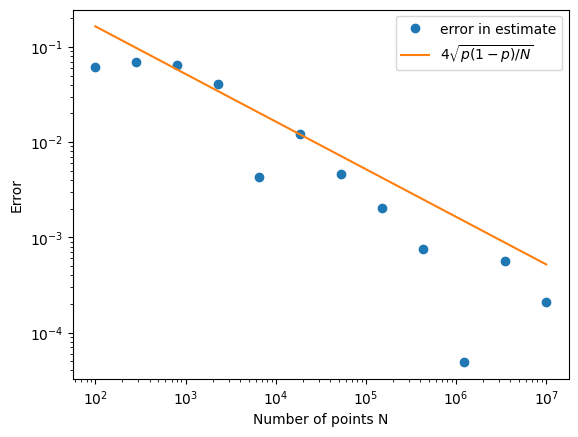

In [8]:
import matplotlib.pyplot as plt

inside = (x[:, 0]**2 + x[:, 1]**2 <= 1)       # True for points inside the circle
cumulative = np.cumsum(inside)                # number of points inside, for the first N points
Ns = np.logspace(2, np.log10(npts), 12).astype(int)
est = 4 * cumulative[Ns - 1] / Ns
for N, e in zip(Ns, est):
    print(f"N = {N:>10,}   estimate = {e:.5f}   error = {abs(e - np.pi):.5f}")

plt.loglog(Ns, np.abs(est - np.pi), 'o', label='error in estimate')
plt.loglog(Ns, 4*np.sqrt((np.pi/4)*(1 - np.pi/4)/Ns), '-', label=r'$4\sqrt{p(1-p)/N}$')
plt.xlabel('Number of points N'); plt.ylabel('Error'); plt.legend(); plt.show()

3. Given the factorised distribution

$P(C,R,D,A,S,F,T) = P(R)P(C)P(D)P(A\vert C)P(F\vert A)P(T\vert F,D) P(S\vert F,T)$

and the univariate distributions given in the code cell below, compute the following quantities using rejection sampling. Verify your answers against the exact solutions computed in Question 1.

In [9]:
import numpy as np
PR = np.array([0.7,0.3])
PC = np.array([0.9,0.1])
PD = np.array([0.5,0.5])
PA_C = np.array([[1.0, 0.99],[0.0,0.01]])
PF_A = np.array([[0.999, 0.7],[0.001,0.3]])
PT_FD = np.array([[[0.99,0.40],[0.30,0.01]],[[0.01,0.60],[0.70,0.99]]])
PS_TF = np.array([[[0.999,0.01],[0.70,0.01]],[[0.001,0.99],[0.30,0.99]]])


In [10]:
# First, generate the trace
N = 100000
Trace = np.zeros([N,7])
for i in range(N):
    R = np.random.binomial(1, PR[1])
    C = np.random.binomial(1, PC[1])
    D = np.random.binomial(1, PD[1])
    A = np.random.binomial(1, PA_C[1,C])
    F = np.random.binomial(1, PF_A[1,A])
    T = np.random.binomial(1, PT_FD[1,F,D])
    S = np.random.binomial(1, PS_TF[1,T,F])
    Trace[i,:] = np.array([R,C,D,A,F,T,S])
    

a) $P(S)$

In [11]:
# Exact calculation
PA = PA_C @ PC
PF = PF_A @ PA
PT_F = PT_FD @ PD
PT = PT_F @ PF
PS = np.einsum('stf,tf,f->s', PS_TF, PT_F, PF)

print(f"P(S) = {Trace[:,6].sum()/N} (expect {PS[1]})")

P(S) = 0.09291 (expect 0.093361248695)


b) $P(S,C)$

In [12]:
# Exact calculation
PT_A = PT_F @ PF_A
PS_A = np.einsum('stf,tf,fa->sa', PS_TF, PT_F, PF_A)
PS_C = PS_A @ PA_C
PSC = PS_C*PC

# P(S=1,C=1)
CEq1 = Trace[np.where(Trace[:,1]==1)]
SEq1CEq1 = CEq1[np.where(CEq1[:,6]==1)]
PSEq1CEq1 = SEq1CEq1.shape[0]/N
print(f"P(S=1,C=1) = {PSEq1CEq1} (expect {PSC[1,1]})")

P(S=1,C=1) = 0.00919 (expect 0.009577724195000002)


c) $P(A\vert S)$

In [13]:
PSA = PS_A * PA
PA_S = PSA.T/PS

# P(A=0|S=0)
SEq0 = Trace[np.where(Trace[:,6]==0)]
AEq0SEq0 = SEq0[np.where(SEq0[:,3]==0)]
PAEq0GivenSEq0 = AEq0SEq0.shape[0]/SEq0.shape[0]
print(f"P(A=0|S=0) = {PAEq0GivenSEq0} (expect {PA_S[0,0]})")

# P(A=1|S=1). This is a rare event so only a few samples contribute and the estimate is noisy
SEq1 = Trace[np.where(Trace[:,6]==1)]
AEq1SEq1 = SEq1[np.where(SEq1[:,3]==1)]
print(f"P(A=1|S=1) = {AEq1SEq1.shape[0]/SEq1.shape[0]} (expect {PA_S[1,1]})")

P(A=0|S=0) = 0.9992944470780187 (expect 0.9992957906342732)
P(A=1|S=1) = 0.004197610590894414 (expect 0.0038724471346896438)


d) $P(A\vert T)$

In [14]:
# Exact calculation
PT_A = PT_F @ PF_A
PTA = PT_A * PA
PA_T = PTA.T/PT

TEq1 = Trace[np.where(Trace[:,5]==1)]
AEq1TEq1 = TEq1[np.where(TEq1[:,3]==1)]
print(f"P(A=1|T=1) = {AEq1TEq1.shape[0]/TEq1.shape[0]} (expect {PA_T[1,1]})")

P(A=1|T=1) = 0.0017343499460060867 (expect 0.0015276341827088428)


4. Given the factorised distribution

$P(C,R,D,A,S,F,T) = P(R)P(C)P(D)P(A\vert C)P(F\vert A)P(T\vert F,D) P(S\vert F,T)$

and the univariate distributions given in the code cell below, compute the following quantities using likelihood reweighting. Verify your answers against the exact solutions computed in Question 1, and the rejection sampling solutions computed in Question 3

In [15]:
import numpy as np
PR = np.array([0.7,0.3])
PC = np.array([0.9,0.1])
PD = np.array([0.5,0.5])
PA_C = np.array([[1.0, 0.99],[0.0,0.01]])
PF_A = np.array([[0.999, 0.7],[0.001,0.3]])
PT_FD = np.array([[[0.99,0.40],[0.30,0.01]],[[0.01,0.60],[0.70,0.99]]])
PS_TF = np.array([[[0.999,0.01],[0.70,0.01]],[[0.001,0.99],[0.30,0.99]]])


a) $P(S\vert C=1, D=0)$

In [16]:
N = 100000
Trace = np.zeros([N,8])
for i in range (N):
    w = 1.0
    R = np.random.binomial(1,PR[1])
    C = 1
    w *= PC[C]
    D = 0
    w *= PD[D]
    A = np.random.binomial(1,PA_C[1,C])
    F = np.random.binomial(1,PF_A[1,A])
    T = np.random.binomial(1,PT_FD[1,F,D])
    S = np.random.binomial(1,PS_TF[1,T,F])
    Trace[i,:] = [R,C,D,A,F,T,S,w]

# P(S=1|C=1,D=0): weighted fraction of the trace in which S=1
PS_weighted = Trace[np.where(Trace[:,6]==1)][:,7].sum()/Trace[:,7].sum()
# Exact calculation, summing over A, F and T
PS_CD = np.einsum('stf,tf,fa,a->s', PS_TF, PT_FD[:,:,0], PF_A, PA_C[:,1])
print(f"P(S=1|C=1,D=0) = {PS_weighted} (expect {PS_CD[1]})")

P(S=1|C=1,D=0) = 0.00844 (expect 0.0079241799)


b) $P(S,C\vert A=1, R=0)$

In [17]:
N = 50000
Trace = np.zeros([N,8])
for i in range (N):
    w = 1.0
    R = 0 
    w *= PR[R]
    C = np.random.binomial(1,PC[1])
    D = np.random.binomial(1,PD[1])
    A = 1
    w *= PA_C[A,C]
    F = np.random.binomial(1,PF_A[1,A])
    T = np.random.binomial(1,PT_FD[1,F,D])
    S = np.random.binomial(1,PS_TF[1,T,F])
    Trace[i,:] = [R,C,D,A,F,T,S,w]

# P(S=1,C=1 | A=1, R=0)
CEq1 = Trace[np.where(Trace[:,1]==1)]
SEq1CEq1 = CEq1[np.where(CEq1[:,6]==1)]
PSEq1CEq1 = SEq1CEq1[:,7].sum() / Trace[:,7].sum()
# Exact: P(A=1|C=0)=0, so A=1 implies C=1 and P(S=1,C=1|A=1,R=0) = P(S=1|A=1)
print(f"P(S=1,C=1|A=1,R=0) = {PSEq1CEq1} (expect {PS_A[1,1]})")


P(S=1,C=1|A=1,R=0) = 0.36093375897845187 (expect 0.3615365)


c) $P(A\vert S, D=1, R=0)$

In [18]:
N = 500000
Trace = np.zeros([N,8])
for i in range (N):
    w = 1.0
    R = 0 
    w *= PR[R]
    C = np.random.binomial(1,PC[1])
    D = 1
    w *= PD[D]
    A = np.random.binomial(1,PA_C[1,C])
    F = np.random.binomial(1,PF_A[1,A])
    T = np.random.binomial(1,PT_FD[1,F,D])
    S = np.random.binomial(1,PS_TF[1,T,F])
    Trace[i,:] = [R,C,D,A,F,T,S,w]

# P(A=1 | S=1, D=1, R=0)
SEq1 = Trace[np.where(Trace[:,6]==1)]
AEq1SEq1 = SEq1[np.where(SEq1[:,3]==1)]
PAEq1SEq1 = AEq1SEq1[:,7].sum() / SEq1[:,7].sum()
# Exact calculation of P(S=1,A|D=1), summing over F and T (and C, which is already in PA)
PSA_D1 = np.einsum('stf,tf,fa,a->sa', PS_TF, PT_FD[:,:,1], PF_A, PA)
print(f"P(A=1|S=1,D=1,R=0) = {PAEq1SEq1} (expect {PSA_D1[1,1]/PSA_D1[1].sum()})")


P(A=1|S=1,D=1,R=0) = 0.002413063599100886 (expect 0.002332742371932444)


d) $P(A\vert T, C=1, D=1)$

In [19]:
N = 200000
Trace = np.zeros([N,8])
for i in range (N):
    w = 1.0
    R = np.random.binomial(1,PR[1])
    C = 1
    w *= PC[C]
    D = 1
    w *= PD[D]
    A = np.random.binomial(1,PA_C[1,C])
    F = np.random.binomial(1,PF_A[1,A])
    T = np.random.binomial(1,PT_FD[1,F,D])
    S = np.random.binomial(1,PS_TF[1,T,F])
    Trace[i,:] = [R,C,D,A,F,T,S,w]

# P(A=1 | T=1, C=1, D=1)
TEq1 = Trace[np.where(Trace[:,5]==1)]
AEq1TEq1 = TEq1[np.where(TEq1[:,3]==1)]
PAEq1TEq1 = AEq1TEq1[:,7].sum() / TEq1[:,7].sum()
# Exact calculation, summing over F
PTA_CD = np.einsum('tf,fa,a->ta', PT_FD[:,:,1], PF_A, PA_C[:,1])
print(f"P(A=1|T=1,C=1,D=1) = {PAEq1TEq1} (expect {PTA_CD[1,1]/PTA_CD[1].sum()})")


P(A=1|T=1,C=1,D=1) = 0.01158561452862695 (expect 0.01191908784567225)


5. Likelihood weighting is more efficient than rejection sampling when the evidence is unlikely. For the network of Question 1, estimate $P(F\vert A=1,S=1)$ using (i) rejection sampling and (ii) likelihood weighting, each with $N=100{,}000$ samples. How many samples does each method effectively use? Compare your estimates with the exact value from enumeration. (The *effective sample size* of a set of weights $w_i$ is $(\sum_iw_i)^2/\sum_iw_i^2$.)

In [20]:
rng = np.random.default_rng(2)
N = 100000
exact = posterior(PCRDASFT, names, 'F', {'A': 1, 'S': 1})
print(f"Exact P(F=1 | A=1, S=1) = {exact[1]:.4f}   (P(A=1, S=1) = {PCRDASFT.sum(axis=(0,1,2,5,6))[1,1]:.2e})")

# (i) Rejection sampling: generate complete samples and keep those with A=1 and S=1
C = rng.binomial(1, PC[1], N)
D = rng.binomial(1, PD[1], N)
A = rng.binomial(1, PA_C[1, C])
F = rng.binomial(1, PF_A[1, A])
T = rng.binomial(1, PT_FD[1, F, D])
S = rng.binomial(1, PS_TF[1, T, F])
keep = (A == 1) & (S == 1)
print(f"Rejection sampling:   {keep.sum()} of {N} samples kept", end="")
print(f",  P(F=1 | A=1, S=1) = {F[keep].mean():.4f}" if keep.any() else "")

# (ii) Likelihood weighting: fix A=1 and weight by P(A=1 | C); fix S=1 and weight by P(S=1 | T, F)
C = rng.binomial(1, PC[1], N)
D = rng.binomial(1, PD[1], N)
w = PA_C[1, C]                                 # evidence A=1
F = rng.binomial(1, PF_A[1, 1], N)             # F given A=1
T = rng.binomial(1, PT_FD[1, F, D])
w = w * PS_TF[1, T, F]                         # evidence S=1
print(f"Likelihood weighting: effective sample size = {w.sum()**2 / (w**2).sum():.0f},  P(F=1 | A=1, S=1) = {(w * F).sum() / w.sum():.4f}")

Exact P(F=1 | A=1, S=1) = 0.8215   (P(A=1, S=1) = 3.62e-04)
Rejection sampling:   27 of 100000 samples kept,  P(F=1 | A=1, S=1) = 0.8889
Likelihood weighting: effective sample size = 4186,  P(F=1 | A=1, S=1) = 0.8256


Only a few dozen of the 100,000 samples agree with the evidence (36 on average), because $P(A=1,S=1)$ is of order $10^{-4}$, so the rejection sampling estimate is based on a handful of samples and is very noisy. Likelihood weighting uses all of the samples. Many of them have zero weight (those with $C=0$, which have $P(A=1\vert C=0)=0$) but a good fraction of them count, giving an effective sample size of several thousand. The sampled value is much closer to the exact one.